# Практична робота №6. Нейромережа для мікроконтролера: датасет → Keras → TFLite int8
**Варіант 5** — класифікація екологічних подій у приміщенні.

У цій клітинці я імпортував необхідні бібліотеки (`numpy`, `matplotlib`, `tensorflow`, `os`), зафіксував генератори випадкових чисел для відтворюваності результатів і задав параметри задачі: 4 класи подій, 4 датчики (`temp`, `hum`, `light`, `co2`), вікно з 60 вимірів, по 300 прикладів на клас та 16 статистичних ознак.

In [3]:
import numpy as np;
import matplotlib.pyplot as plt;
import tensorflow as tf, os

rng = np.random.default_rng(42)
tf.random.set_seed(42)

N_PER_CLASS = 300    # кількість прикладів на клас
WINDOW = 60          # кількість вимірів у ковзному вікні

CLASSES = ["звичайний", "відкрите вікно", "багато людей", "вентиляція"]
SENSORS = ["temp", "hum", "light", "co2"]
TARGET_KB = 10
STATS = ["mean", "std", "min", "max"]
FEATURES = [f"{s}_{st}" for s in SENSORS for st in STATS]
print(len(FEATURES), "ознак,", len(CLASSES), "класи")

16 ознак, 4 класи


## Завдання 1. Генерація та підготовка синтетичного датасету
У цій клітинці я реалізував генерацію синтетичних показань датчиків у вікні з 60 вимірів для кожного класу (з трендами, коливаннями та шумом), обчислив статистичні ознаки, перемішав датасет, розділив його у співвідношенні 70/15/15 і виконав Z-нормалізацію за статистиками навчальної вибірки.

In [4]:
t = np.linspace(0, 1, WINDOW)

def window_env(cls):
    """Генерація одного вікна показань: 4 датчики × WINDOW вимірів."""
    j = lambda a, b: rng.uniform(a, b)           # випадковий параметр у діапазоні
    n = lambda s: rng.normal(0, s, WINDOW)       # нормальний шум
    if cls == 0:   # звичайний стан
        temp = j(21, 24) + j(-0.4, 0.4) * t + n(0.3); hum = j(38, 52) + n(1.2)
        light = j(250, 600) + n(30);             co2 = j(500, 950) + j(-60, 80) * t + n(30)
    elif cls == 1: # відкрите вікно: зниження температури та CO2, зміна вологості
        temp = j(20, 24) - j(0.2, 2.5) * t + n(0.3); hum = j(38, 55) + j(-5, 6) * t + n(1.5)
        light = j(250, 650) + n(30);             co2 = j(550, 1000) - j(20, 300) * t + n(30)
    elif cls == 2: # багато людей: зростання CO2 і температури
        temp = j(21.5, 25) + j(0, 1.5) * t + n(0.3); hum = j(42, 58) + j(0, 4) * t + n(1.2)
        light = j(300, 700) + n(30);             co2 = j(700, 1150) + j(20, 350) * t + n(30)
    else:          # вентиляція/кондиціонер: циклічна температура, нижча вологість
        temp = j(21, 24) + j(0.05, 0.5) * np.sin(2 * np.pi * j(2, 4) * t) + n(0.25)
        hum = j(32, 47) + n(1.0);                light = j(250, 600) + n(30)
        co2 = j(500, 900) - j(0, 150) * t + n(30)
    return np.stack([temp, hum, light, co2])

def features(w):
    return np.concatenate([[r.mean(), r.std(), r.min(), r.max()] for r in w])

X = np.array([features(window_env(c)) for c in range(len(CLASSES)) for _ in range(N_PER_CLASS)], dtype=np.float32)
y = np.repeat(np.arange(len(CLASSES)), N_PER_CLASS)

# перемішування та поділ на вибірки (70 / 15 / 15)
idx = rng.permutation(len(X)); X, y = X[idx], y[idx]
n_tr, n_va = int(0.7 * len(X)), int(0.15 * len(X))
X_tr, y_tr = X[:n_tr], y[:n_tr]
X_va, y_va = X[n_tr:n_tr + n_va], y[n_tr:n_tr + n_va]
X_te, y_te = X[n_tr + n_va:], y[n_tr + n_va:]

# нормалізація за статистиками навчального набору
MU, SD = X_tr.mean(0), X_tr.std(0) + 1e-6
X_tr, X_va, X_te = [(a - MU) / SD for a in (X_tr, X_va, X_te)]
print(f"навчальний: {len(X_tr)}, валідаційний: {len(X_va)}, тестовий: {len(X_te)}")

навчальний: 840, валідаційний: 180, тестовий: 180


У цій клітинці я візуалізував по 5 нормалізованих векторів ознак для кожного класу для оцінки їхнього розподілу й перекриття та зберіг графік у файл `samples.png`.

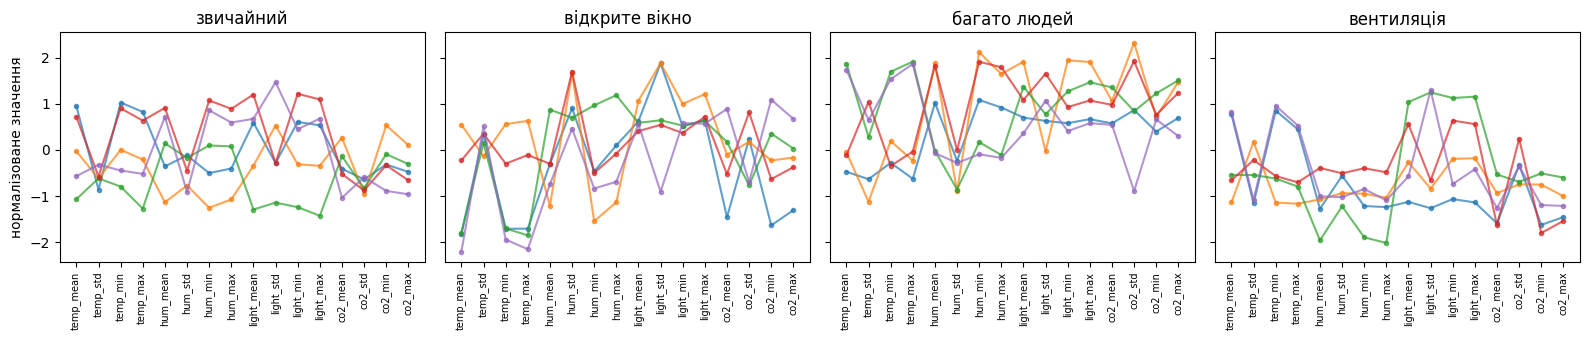

In [5]:
# 5 прикладів векторів ознак для кожного класу
fig, axes = plt.subplots(1, len(CLASSES), figsize=(16, 3.5), sharey=True)
for c, ax in enumerate(axes):
    for v in X_tr[y_tr == c][:5]: ax.plot(v, marker=".", alpha=0.7)
    ax.set_title(CLASSES[c]); ax.set_xticks(range(len(FEATURES)))
    ax.set_xticklabels(FEATURES, rotation=90, fontsize=7)
axes[0].set_ylabel("нормалізоване значення")
plt.tight_layout(); plt.savefig("samples.png", dpi=150); plt.show()

## Завдання 2. Побудова та навчання нейромережі в Keras
У цій клітинці я створив компактну повнозв'язну нейромережу (`Dense(24) → Dense(16) → Dense(4)`), скомпілював її з оптимізатором `adam`, навчив із ранньою зупинкою (`EarlyStopping`) на валідаційній вибірці та побудував графіки втрат і точності (`training.png`).

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 24)             │           408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 4)              │            68 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 876 (3.42 KB)

 Trainable params: 876 (3.42 KB)

 Non-trainable params: 0 (0.00 B)

епох: 58


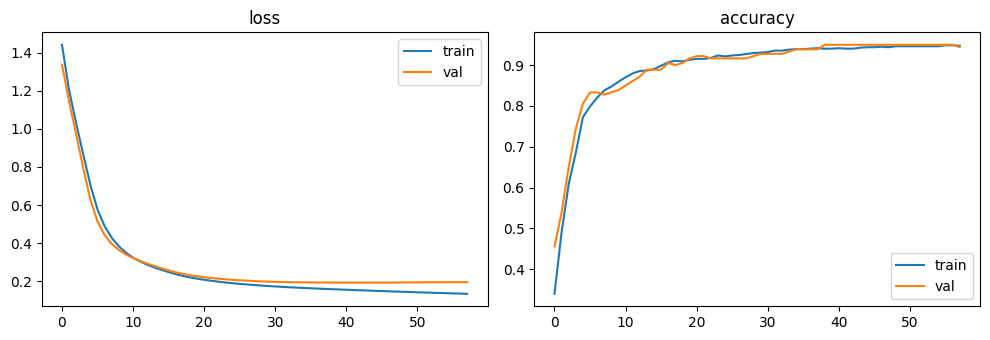

In [6]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(len(FEATURES),)),
    tf.keras.layers.Dense(24, activation="relu"),
    tf.keras.layers.Dense(16, activation="relu"),
    tf.keras.layers.Dense(len(CLASSES), activation="softmax"),
])
model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model.summary()

# рання зупинка навчання при відсутності покращення на валідації
hist = model.fit(X_tr, y_tr, validation_data=(X_va, y_va), epochs=200, batch_size=32, verbose=0,
                 callbacks=[tf.keras.callbacks.EarlyStopping(patience=15, restore_best_weights=True)])
print("епох:", len(hist.history["loss"]))

plt.figure(figsize=(10, 3.5))
plt.subplot(1, 2, 1); plt.plot(hist.history["loss"], label="train"); plt.plot(hist.history["val_loss"], label="val"); plt.title("loss"); plt.legend()
plt.subplot(1, 2, 2); plt.plot(hist.history["accuracy"], label="train"); plt.plot(hist.history["val_accuracy"], label="val"); plt.title("accuracy"); plt.legend()
plt.tight_layout(); plt.savefig("training.png", dpi=150); plt.show()

У цій клітинці я оцінив точність навченої моделі на тестовій вибірці, підрахував кількість параметрів і обсяг ваг у `float32`, а також зберіг модель у файл `model.keras`.

In [7]:
_, acc_keras = model.evaluate(X_te, y_te, verbose=0)
params = model.count_params()
model.save("model.keras")
print(f"точність на тесті: {acc_keras:.3f}")
print(f"параметрів: {params}, float32 = {params * 4 / 1024:.2f} КБ (лише ваги), файл .keras = {os.path.getsize('model.keras') / 1024:.1f} КБ")

точність на тесті: 0.939
параметрів: 876, float32 = 3.42 КБ (лише ваги), файл .keras = 35.2 КБ


## Завдання 3. Конвертація у TFLite (`float32` та `int8`)
У цій клітинці я конвертував модель у формат TFLite (`float32`), виконав повне цілочисельне квантування в `int8` із калібруванням на репрезентативній вибірці, оцінив точність обох версій на тестових даних і порівняв їхній розмір із цільовим обмеженням пам'яті.

In [8]:
conv = tf.lite.TFLiteConverter.from_keras_model(model)
tfl_f32 = conv.convert()
open("model_f32.tflite", "wb").write(tfl_f32)

def representative():
    # репрезентативна вибірка для калібрування квантування int8
    for v in X_tr[:200]:
        yield [v.reshape(1, -1).astype(np.float32)]

conv = tf.lite.TFLiteConverter.from_keras_model(model)
conv.optimizations = [tf.lite.Optimize.DEFAULT]
conv.representative_dataset = representative
conv.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
conv.inference_input_type = tf.int8     # повністю цілочисельна модель (int8)
conv.inference_output_type = tf.int8
tfl_i8 = conv.convert()
open("model_int8.tflite", "wb").write(tfl_i8)

def tflite_accuracy(blob):
    it = tf.lite.Interpreter(model_content=blob); it.allocate_tensors()
    inp, out = it.get_input_details()[0], it.get_output_details()[0]
    ok = 0
    for v, lbl in zip(X_te, y_te):
        x = v.reshape(1, -1)
        if inp["dtype"] == np.int8:                       # квантування вхідного вектора
            s, z = inp["quantization"]; x = np.round(x / s + z).astype(np.int8)
        it.set_tensor(inp["index"], x.astype(inp["dtype"])); it.invoke()
        ok += int(np.argmax(it.get_tensor(out["index"])) == lbl)
    return ok / len(y_te)

rows = [("Keras float32", os.path.getsize("model.keras"), acc_keras),
        ("TFLite float32", len(tfl_f32), tflite_accuracy(tfl_f32)),
        ("TFLite int8", len(tfl_i8), tflite_accuracy(tfl_i8))]
print(f"{'Модель':<16}{'Розмір, КБ':>12}{'Точність':>10}")
for name, size, acc in rows: print(f"{name:<16}{size / 1024:>12.2f}{acc:>10.3f}")
print(f"\nОбмеження (< {TARGET_KB} КБ): int8 {'вкладається' if len(tfl_i8) / 1024 < TARGET_KB else 'НЕ вкладається'}")

Saved artifact at '/tmp/tmp7rgpel5d'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 16), dtype=tf.float32, name='keras_tensor')
Output Type:
  TensorSpec(shape=(None, 4), dtype=tf.float32, name=None)
Captures:
  134886212954896: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134886212959312: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134886212958928: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134886212952784: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134886212958736: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134886212959120: TensorSpec(shape=(), dtype=tf.resource, name=None)
Saved artifact at '/tmp/tmpjw0255yb'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 16), dtype=tf.float32, name='keras_tensor')
Output Type:
  TensorSpec(shape=(None, 4), dtype=tf.float32, name=None)
Captures:
  134886212954896: TensorSpec(

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


## Завдання 4. Параметри тензорів для Netron та збереження результатів
У цій клітинці я вивів форми, типи даних і параметри квантування входу та виходу для обох моделей TFLite (для перевірки графу в Netron) і зберіг згенеровані файли.

In [9]:
for name, blob in [("float32", tfl_f32), ("int8", tfl_i8)]:
    it = tf.lite.Interpreter(model_content=blob)
    i, o = it.get_input_details()[0], it.get_output_details()[0]
    print(f"{name}: вхід {i['shape']} {i['dtype'].__name__} q={i['quantization']}, "
          f"вихід {o['shape']} {o['dtype'].__name__} q={o['quantization']}")

try:
    from google.colab import files
    for f in ["model_f32.tflite", "model_int8.tflite", "samples.png", "training.png"]: files.download(f)
except ImportError:
    print("Локальний запуск: файли збережено в поточній директорії")

float32: вхід [ 1 16] float32 q=(0.0, 0), вихід [1 4] float32 q=(0.0, 0)
int8: вхід [ 1 16] int8 q=(0.025412851944565773, -1), вихід [1 4] int8 q=(0.00390625, -128)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>